# Two-compartment PK with default filtering, LatentPathBuilder, and NUTS

An IV bolus enters the central compartment. Drug exchanges between the central
amount $x_c$ and the peripheral amount $x_p$, and leaves through the central
compartment at rate $k_{10}$.

$$
\frac{d}{dt}
\begin{bmatrix}x_c\\x_p\end{bmatrix}
=
\begin{bmatrix}
-(k_{10}+k_{12}) & k_{21}\\
k_{12} & -k_{21}
\end{bmatrix}
\begin{bmatrix}x_c\\x_p\end{bmatrix},
\qquad
y_i \sim \mathcal{N}(x_c(t_i),\sigma^2).
$$

This synthetic example fixes $k_{10}$ and the observation noise. A tight
initial-state distribution centers the normalized dose at $(1,0)$. We fit
$k_{12}$ and $k_{21}$ from six central observations. The first post-dose
sample is at 1.2 minutes, after most of the fast exchange transient has
decayed.

In [1]:
import arviz_stats as azs
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist

import dynestyx as dsx
from dynestyx.inference.configs.mcmc import NUTSConfig
from dynestyx.inference.mcmc import MCMCInference

SEED = 0
simulation_key, nuts_key = jr.split(jr.PRNGKey(SEED))
latent_nuts_key = jr.fold_in(nuts_key, 1)

K10 = 3.5  # per hour
TRUE_RATES = jnp.array([420.0, 140.0])  # k12 and k21 per hour
X0 = jnp.array([1.0, 0.0])
X0_SD = 1e-3
OBS_SD = 0.015
LOG_RATE_MIN = jnp.log(jnp.array([80.0, 30.0]))
LOG_RATE_MAX = jnp.log(jnp.array([1600.0, 600.0]))


def pk_dynamics(k12, k21):
    A = jnp.array([[-(K10 + k12), k21], [k12, -k21]])
    return dsx.DynamicalModel(
        initial_condition=dist.MultivariateNormal(
            X0, covariance_matrix=X0_SD**2 * jnp.eye(2)
        ),
        state_evolution=dsx.ContinuousTimeStateEvolution(
            drift=dsx.AffineDrift(A=A)
        ),
        observation_model=dsx.LinearGaussianObservation(
            H=jnp.array([[1.0, 0.0]]), R=jnp.array([[OBS_SD**2]])
        ),
        control_dim=0,
    )


def pk_model(obs_times, obs_values, ctrl_times=None, ctrl_values=None):
    log_rates = numpyro.sample(
        "log_rates", dist.Uniform(LOG_RATE_MIN, LOG_RATE_MAX).to_event(1)
    )
    k12, k21 = jnp.exp(log_rates)
    return dsx.sample(
        "pk", pk_dynamics(k12, k21), obs_times=obs_times, obs_values=obs_values
    )

## Simulate the sparse observations

`dsx.simulate` selects the default ODE simulator for this model. The ODE
has a fast time constant of about 6.4 seconds and a slow time constant of
about 69 minutes at the simulated rates. The dense curve shows the simulated
central state. We keep one observation every 1.2 minutes, for six in total.

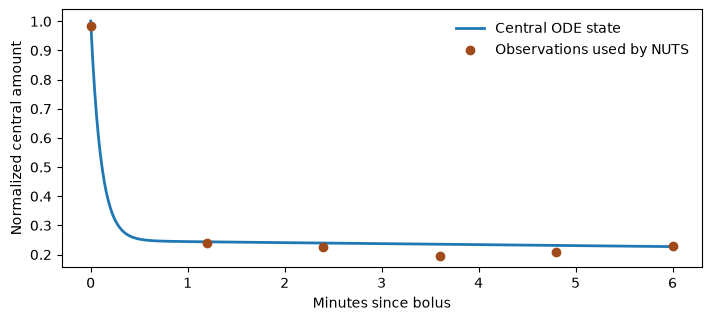

In [2]:
dynamics = pk_dynamics(*TRUE_RATES)
plot_times = jnp.linspace(0.0, 0.10, 301)  # hours
synthetic = dsx.simulate(dynamics, rng_key=simulation_key, predict_times=plot_times)
obs_times = plot_times[::60]
obs_values = synthetic.observations[0, ::60]

fig, ax = plt.subplots(figsize=(7, 3.1), layout="constrained")
ax.plot(60 * plot_times, synthetic.states[0, :, 0], lw=2, label="Central ODE state")
ax.scatter(
    60 * obs_times, obs_values[:, 0],
    color="#a04b19", zorder=3, label="Observations used by NUTS",
)
ax.set(xlabel="Minutes since bolus", ylabel="Normalized central amount")
ax.legend(frameon=False)
plt.show()

## Fit the exchange rates with NUTS and Dynestyx default (here, an EnKF which marginalizes out the un-observed initial condition and stabilizes the likelihood computation)

For this problem, Dynestyx 0.8.1 defaults to computing a marginal likelihood via an 
ensemble Kalman filter---it chooses this due to the partially-observed structure, which can be very difficult to resolve by simply rolling out the ODE (shown later). 
The default ODE flow uses fixed-step Tsit5 with
$\Delta t=10^{-3}$ hours. NUTS uses that filter's approximate likelihood,
with the default 30-member ensemble and fixed filter seed. The run specifies
the sampler backend and chain lengths. NUTS uses its default initialization
and target acceptance probability of 0.8.

Both fits below use four chains, each with 250 warmup steps and 400 retained
draws. NumPyro runs the chains sequentially when only one JAX device is available.

In [3]:
n_warmup, n_draws, n_chains = 250, 400, 4
config = NUTSConfig(
    num_warmup=n_warmup,
    num_samples=n_draws,
    num_chains=n_chains,
    mcmc_source="numpyro",
)
inference = MCMCInference(config, pk_model)
posterior = inference.run(nuts_key, obs_times, obs_values)
log_rates = np.asarray(posterior["log_rates"]).reshape(n_chains, n_draws, 2)
rates = np.exp(log_rates)
diagnostics = inference.get_diagnostics()

/Users/danwaxman/Documents/dynestyx/dynestyx/inference/mcmc.py:127: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(



  0%|          | 0/650 [00:00<?, ?it/s]


  0%|          | 0/650 [00:00<?, ?it/s]


  0%|          | 0/650 [00:00<?, ?it/s]


  0%|          | 0/650 [00:00<?, ?it/s]

## Fit the same model with `dsx.LatentPathBuilder`, which "rolls out" the ODE and tries to learn its initial conditions along with parameters.

Reuse `pk_model`, the observations, priors, and NUTS configuration. The explicit
`dsx.LatentPathBuilder` handler replaces the default filtering likelihood. For this deterministic ODE,
`pk_state_path_params` contains only the two initial-state coordinates; the
remaining path is reconstructed by solving the ODE. NUTS therefore samples the
initial state jointly with the two log exchange rates, and the observations are
scored with their Gaussian likelihood. The builder uses its default fixed-step
Tsit5 solver with $\Delta t=10^{-3}$ hours.

Keep one builder instance around the entire run so that its observation-layout
cache is available during tracing. Use an independent random key for this fit.

In [4]:
latent_builder = dsx.LatentPathBuilder()
latent_inference = MCMCInference(config, pk_model)
with latent_builder:
    latent_posterior = latent_inference.run(latent_nuts_key, obs_times, obs_values)
latent_log_rates = np.asarray(latent_posterior["log_rates"]).reshape(n_chains, n_draws, 2)
latent_diagnostics = latent_inference.get_diagnostics()


  0%|          | 0/650 [00:00<?, ?it/s]


  0%|          | 0/650 [00:00<?, ?it/s]


  0%|          | 0/650 [00:00<?, ?it/s]


  0%|          | 0/650 [00:00<?, ?it/s]

## Inspect the ridge

Once the fast transient decays, the central fraction is approximately
$k_{21}/(k_{12}+k_{21})$ when exchange is much faster than elimination.
Scaling both rates together leaves that fraction unchanged. In the joint
plot this gives a positively sloped ridge. Compare the spread in
$k_{12}/k_{21}$ with the spread in $\sqrt{k_{12}k_{21}}$ and check whether
the chains cover the same part of the ridge.

The same plots and summaries are shown for each method, with one color per
chain. Compare the posterior intervals, R-hat, bulk ESS, and divergences to
assess agreement and mixing; 400 draws per chain may still be short for this ridge.

- When using Dynestyx defaults, we get good mixing, a large effective sample size, and an overall reliable resolution of the full ridge from each chain of NUTS
- When overriding the default with `dsx.LatentPathBuilder`, the resulting MCMC results show chains that don't mix reliably, have divergences, and a small effective sample size.

We note that `dsx.LatentPathBuilder` is sometimes the best method, which is why we support it---in fact, it is our default choice in fully observed settings in small-data regimes.

Default EnKF


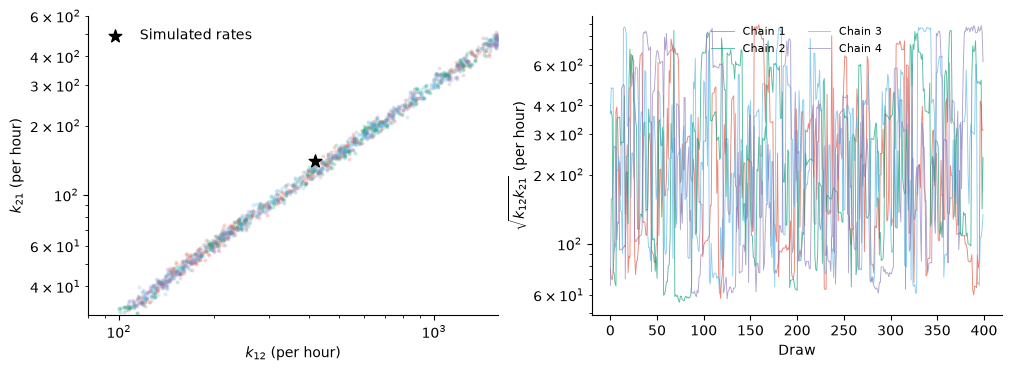

k12 (per hour)               408.68 [ 123.87, 1441.79]   R-hat 1.026   bulk ESS 165
k21 (per hour)               125.18 [  36.65,  434.74]   R-hat 1.026   bulk ESS 167
k12 / k21                      3.30 [   3.08,    3.54]   R-hat 1.002   bulk ESS 1241
sqrt(k12 × k21) (per hour)   226.89 [  67.77,  788.90]   R-hat 1.026   bulk ESS 165
Rows report median [5%, 95%]. R-hat and ESS use log coordinates.
Divergences per chain [0 0 0 0]
LatentPathBuilder


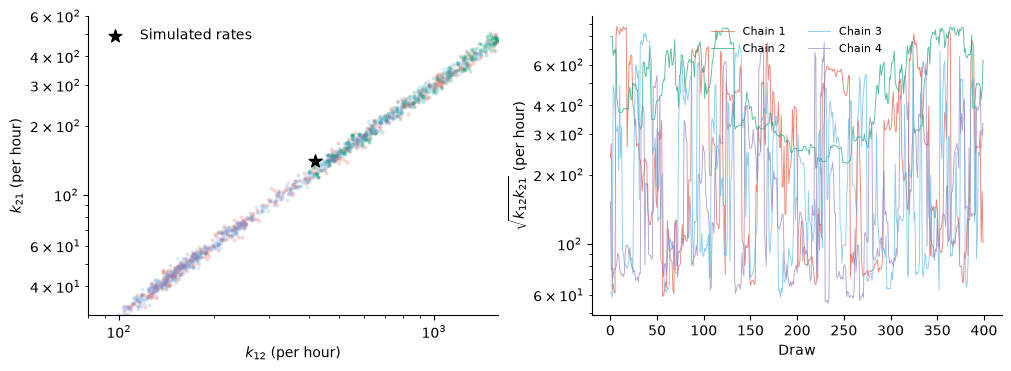

k12 (per hour)               470.20 [ 126.31, 1383.26]   R-hat 1.169   bulk ESS 17
k21 (per hour)               142.09 [  38.08,  416.05]   R-hat 1.168   bulk ESS 17
k12 / k21                      3.30 [   3.07,    3.55]   R-hat 1.011   bulk ESS 1606
sqrt(k12 × k21) (per hour)   260.21 [  69.20,  755.55]   R-hat 1.168   bulk ESS 17
Rows report median [5%, 95%]. R-hat and ESS use log coordinates.
Divergences per chain [ 0 13  0  0]


In [5]:
def inspect_ridge(log_rates, diagnostics, label):
    print(label)
    rates = np.exp(log_rates)
    log_ratio = log_rates[..., 0] - log_rates[..., 1]
    log_speed = log_rates.mean(axis=-1)
    fig, (joint, trace) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
    colors = ["#E64B35", "#009E73", "#56B4E9", "#8C79B8"]
    for chain, chain_rates in enumerate(rates):
        joint.scatter(*chain_rates.T, s=8, alpha=0.23, linewidths=0, color=colors[chain])
        trace.plot(np.exp(log_speed[chain]), lw=0.65, alpha=0.68, color=colors[chain], label=f"Chain {chain + 1}")

    joint.scatter(*TRUE_RATES, marker="*", color="black", s=90, label="Simulated rates")
    joint.set(
        xscale="log", yscale="log",
        xlim=np.exp([LOG_RATE_MIN[0], LOG_RATE_MAX[0]]),
        ylim=np.exp([LOG_RATE_MIN[1], LOG_RATE_MAX[1]]),
        xlabel=r"$k_{12}$ (per hour)", ylabel=r"$k_{21}$ (per hour)",
    )
    joint.legend(frameon=False, loc="upper left")
    trace.set(
        yscale="log", xlabel="Draw",
        ylim=np.exp([np.mean(LOG_RATE_MIN), np.mean(LOG_RATE_MAX)]),
        ylabel=r"$\sqrt{k_{12}k_{21}}$ (per hour)",
    )
    trace.legend(frameon=False, ncols=2, fontsize=8)
    for ax in (joint, trace):
        ax.spines[["top", "right"]].set_visible(False)
    plt.show()

    for label, log_quantity in [
        ("k12 (per hour)", log_rates[..., 0]),
        ("k21 (per hour)", log_rates[..., 1]),
        ("k12 / k21", log_ratio),
        ("sqrt(k12 × k21) (per hour)", log_speed),
    ]:
        lower, median, upper = np.quantile(np.exp(log_quantity), [0.05, 0.50, 0.95])
        print(
            f"{label:27s} {median:7.2f} [{lower:7.2f}, {upper:7.2f}]"
            f"   R-hat {azs.rhat(log_quantity):.3f}"
            f"   bulk ESS {azs.ess(log_quantity, method='bulk'):.0f}"
        )
    print("Rows report median [5%, 95%]. R-hat and ESS use log coordinates.")
    print("Divergences per chain", np.asarray(diagnostics["num_divergences"]))


inspect_ridge(log_rates, diagnostics, "Default EnKF")
inspect_ridge(latent_log_rates, latent_diagnostics, "LatentPathBuilder")

The summaries above report median and 90% posterior intervals for each method.
The ratio is informed by the central fraction, while the geometric mean measures
motion along the less identified exchange-speed direction. Check all four chains
and the diagnostics before interpreting differences between the default EnKF
approximation and the explicit ODE likelihood. Neither fit resolves the lack of
early observations by itself.

In this four-chain run, both methods give a ratio near 3.30, with similar 90%
intervals (about 3.08–3.54 for EnKF and 3.07–3.55 for LatentPathBuilder).
Exploration along the ridge is less reliable: the geometric mean has R-hat
1.026 and bulk ESS 165 for EnKF, versus R-hat 1.168 and bulk ESS 17 for
LatentPathBuilder. EnKF has no divergences; LatentPathBuilder has 13, all in one
chain. These short runs illustrate the geometry but do not establish convergence
of the exchange-speed posterior; longer warmup/sampling and sampler tuning would
be needed before treating that posterior as reliable.